## `pybiglasso` Basic Demo

This notebook gives some examples of how to fit an elastic net model from an in-memory or memmapped numpy array, and receive the output.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [3]:
import tempfile
import logging

import numpy as np
import plotnine as p9

import pybiglasso as bl

# -- quiet timing info to keep nb clean
logging.getLogger("pybiglasso").setLevel(logging.WARNING)

### Usage with in-memory design matrix

In [4]:
test_data = bl.common.make_biglasso_dataset(nrow=1000, ncol=10)
X, y = test_data["X"], test_data["y"]

X.shape
y.shape

(1000, 10)

(1000,)

In [5]:
bl.biglasso(X, y, alpha=0.8, nlambda=10)

{'df_ncol':   feature  center     scale  penalty_factor  feature_retained
 0      c0   0.078  0.271875             1.0              True
 1      c1   0.050  0.217945             1.0              True
 2      c2   1.981  0.136525             1.0              True
 3      c3   1.377  0.663981             1.0              True
 4      c4   0.168  0.379178             1.0              True
 5      c5   1.484  0.619471             1.0              True
 6      c6   1.613  0.565005             1.0              True
 7      c7   1.943  0.231843             1.0              True
 8      c8   0.687  0.690674             1.0              True
 9      c9   1.522  0.594572             1.0              True,
 'df_nlambda':      deviance   lambda_  iterations  num_rejected
 0  552.229869  0.104210           0            10
 1  537.883974  0.048370           4             0
 2  529.321781  0.022451           6             0
 3  525.798533  0.010421           6             0
 4  524.400393  0.004837  

### Usage with on-disk memory-mapped design matrix

In [6]:
_, mm_name = tempfile.mkstemp()

Xmm = np.lib.format.open_memmap(mm_name, mode="w+", dtype=X.dtype, shape=X.shape, fortran_order=True)
Xmm[:] = X[:]
del Xmm

Xmm = np.lib.format.open_memmap(mm_name, mode="c")
Xmm.shape

(1000, 10)

In [7]:
bl.biglasso(Xmm, y, alpha=0.8, nlambda=10)

{'df_ncol':   feature  center     scale  penalty_factor  feature_retained
 0      c0   0.078  0.271875             1.0              True
 1      c1   0.050  0.217945             1.0              True
 2      c2   1.981  0.136525             1.0              True
 3      c3   1.377  0.663981             1.0              True
 4      c4   0.168  0.379178             1.0              True
 5      c5   1.484  0.619471             1.0              True
 6      c6   1.613  0.565005             1.0              True
 7      c7   1.943  0.231843             1.0              True
 8      c8   0.687  0.690674             1.0              True
 9      c9   1.522  0.594572             1.0              True,
 'df_nlambda':      deviance   lambda_  iterations  num_rejected
 0  552.229869  0.104210           0            10
 1  537.883974  0.048370           4             0
 2  529.321781  0.022451           6             0
 3  525.798533  0.010421           6             0
 4  524.400393  0.004837  

### Plotting

The package includes functions to plot the standard elastic net plot of the regression coefficients along the lambda path, and to plot deviance as a function of lambda.

site-packages/mizani/palettes.py:397: UserWarning: Warning message:Brewer palette Accent has a maximum of 8 colors Returning the palette you asked for with that many colors
site-packages/mizani/palettes.py:397: UserWarning: Warning message:Brewer palette Accent has a maximum of 8 colors Returning the palette you asked for with that many colors


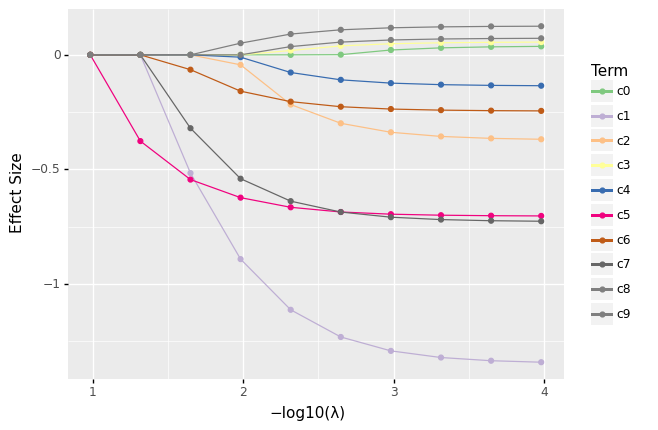

<ggplot: (8737255689012)>

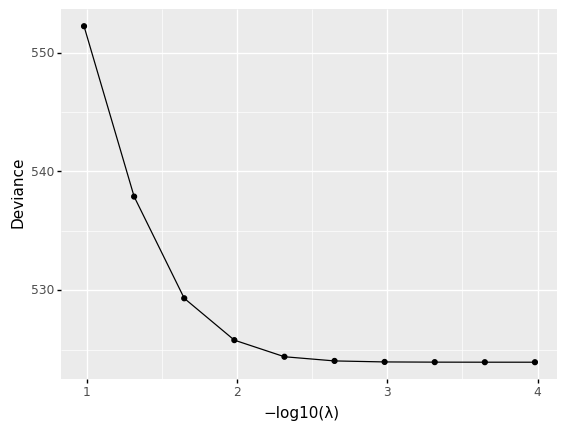

<ggplot: (8737288904003)>

In [8]:
results = bl.biglasso(Xmm, y, alpha=0.8, nlambda=10)

bl.plot_effects(results)

bl.plot_deviance(results)

### Prediction

To form predictions based on a fitted biglasso model, use the `predict()` method.

It returns an ndarray of shape (`nrow`, `nlambda`), where `nrow` is the number of rows in the X matrix, and `nlambda` is the number of lambda values requested from the optional `lam` argument to predict. If no `lam` argument is supplied, predictions are formed for all lambda values present in the biglasso fit object, here `bl_fit`.

In [9]:
bl_fit = bl.biglasso(X, y, alpha=0.8, nlambda=10)

predictions = bl.predict(bl_fit, X)

type(predictions)
predictions.shape

numpy.ndarray

(1000, 10)

In [10]:
# -- take middle few lambda values out of fit object
target_lambdas = bl_fit["df_weights"].index.to_numpy()[3:6]

# -- and take a subset of X
Xs = X[:200, :]

predictions = bl.predict(bl_fit, Xs, lam=target_lambdas)

type(predictions)
predictions.shape

numpy.ndarray

(200, 3)

In [11]:
# -- transform prediction output type

pred_logit = bl.predict(bl_fit, X, output="logit") # default
pred_prob = bl.predict(bl_fit, X, output="prob")
pred_class = bl.predict(bl_fit, X, output="class")

five_num = lambda a: np.asarray([a.min()] + list(np.percentile(a, [25, 50, 75])) + [a.max()]).round(2)

five_num(pred_logit)
five_num(pred_prob)
five_num(pred_class)

array([-3.38, -1.53, -1.15, -0.93,  0.66])

array([0.03, 0.18, 0.24, 0.28, 0.66])

array([0., 0., 0., 0., 1.])

### Model Selection

To choose amongst the models, a `select_model` method is provided, that expects a validation set.

(No cross-validation method is currently implemented.)

In [12]:
# -- make a little larger train/test set
test_data = bl.common.make_biglasso_dataset(
    nrow=10000, ncol=100,
    proportion_associated_markers=0.10,
    marker_effect_sd=0.5
)
X, y = test_data["X"], test_data["y"]

ntrain = int(0.8 * X.shape[0])

Xtrain, ytrain = X[:ntrain, :], y[:ntrain]
Xval, yval = X[ntrain:, :], y[ntrain:]
Xtrain, Xval = map(np.asfortranarray, (Xtrain, Xval))

bl_fit = bl.biglasso(Xtrain, ytrain, alpha=0.8, nlambda=51)

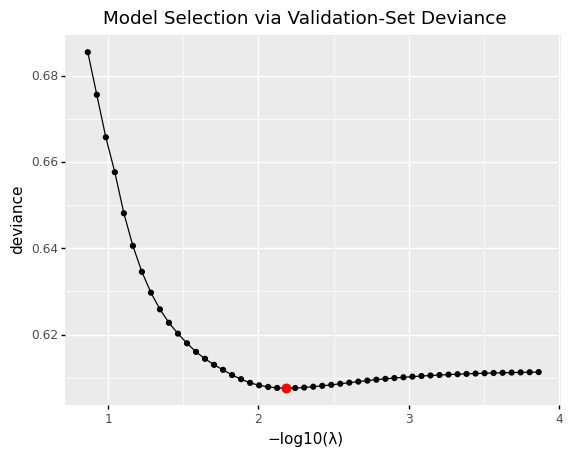

<ggplot: (8737289023467)>

In [13]:
val_deviance_df = bl.select_model(bl_fit, Xval, yval)
best_model_df = val_deviance_df.loc[lambda f: f.deviance == f.deviance.min()]

(p9.ggplot(val_deviance_df, p9.aes(x="-np.log10(lam)", y="deviance")) +
 p9.geom_line() +
 p9.geom_point() +
 p9.geom_point(p9.aes(x="-np.log10(lam)", y="deviance"), best_model_df, color="red", size=3) +
 p9.labs(x="−log10(λ)") +
 p9.ggtitle("Model Selection via Validation-Set Deviance")
)

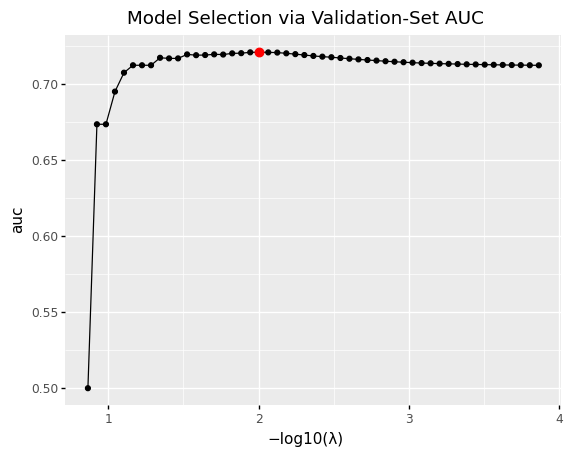

<ggplot: (8737289299556)>

In [14]:
val_auc_df = bl.select_model(bl_fit, Xval, yval, stat="auc")
best_model_df = val_auc_df.loc[lambda f: f.auc == f.auc.max()]

(p9.ggplot(val_auc_df, p9.aes(x="-np.log10(lam)", y="auc")) +
 p9.geom_line() +
 p9.geom_point() +
 p9.geom_point(p9.aes(x="-np.log10(lam)", y="auc"), best_model_df, color="red", size=3) +
 p9.labs(x="−log10(λ)") +
 p9.ggtitle("Model Selection via Validation-Set AUC")
)

### Performance Comparison: `pybiglasso` vs R biglasso

TL;DR Performance is fairly similar, with `pybiglasso` somewhat faster than R biglasso as problem size increases.

To get some sense of the performance of the `pybiglasso` port relative to the R original, we ran some benchmarks, varying the design matrix size (via `nrow`, `ncol`) and the size of the lambda grid (`nlambda`). For these tests, the alpha value was always 0.8, we just ran a single repetition of each benchmark, and we used the memory-mapped file option in either package.

Findings:

1. In our smaller problem sizes `pybiglasso` is modestly faster than R biglasso; the median percent decrease in running time over the present set of benchmarks is 8%, with R biglasso up to 21% faster for some problems, and `pybiglasso` up to 21% faster for others. `pybiglasso` tended to be faster for the larger sample size problems.

2. In a cursory check for linearity, it seems that both `pybiglasso` and R `biglasso` appear to be roughly linear in number of rows, number of columns, and number of lambda values, with respect to time, at least in the benchmarks examined.


The benchmarking script itself is located here ([ref](scripts/benchmark_vs_R_biglasso.py)), the script to reproduce these benchmarks is here ([ref](scripts/run_benchmarks.sh)), and the results data are here ([ref](data/benchmarks.csv)).


In [15]:
import pandas as pd
import plotnine as p9
from plotnine import ggplot, aes

_ = p9.themes.theme_set(p9.theme_seaborn)
_ = p9.theme_update(text=p9.element_text(family="Noto Sans"))


In [16]:
# -- load the benchmark data, and cast the runtimes into a `timedelta` dtype
df = (pd.read_csv("data/benchmarks.csv", sep=" ")
      .assign(
          time=lambda f: pd.to_timedelta(f.time_ms, unit="ms"),
      )
     )
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype          
---  ------   --------------  -----          
 0   program  72 non-null     object         
 1   time_ms  72 non-null     int64          
 2   nrow     72 non-null     float64        
 3   ncol     72 non-null     int64          
 4   nlambda  72 non-null     int64          
 5   alpha    72 non-null     float64        
 6   nreps    72 non-null     int64          
 7   dtype    72 non-null     object         
 8   time     72 non-null     timedelta64[ns]
dtypes: float64(2), int64(4), object(2), timedelta64[ns](1)
memory usage: 5.2+ KB


site-packages/plotnine/facets/facet_grid.py:136: FutureWarning: Index.__and__ operating as a set operation is deprecated, in the future this will be a logical operation matching Series.__and__.  Use index.intersection(other) instead
site-packages/plotnine/facets/facet_grid.py:137: FutureWarning: Index.__and__ operating as a set operation is deprecated, in the future this will be a logical operation matching Series.__and__.  Use index.intersection(other) instead


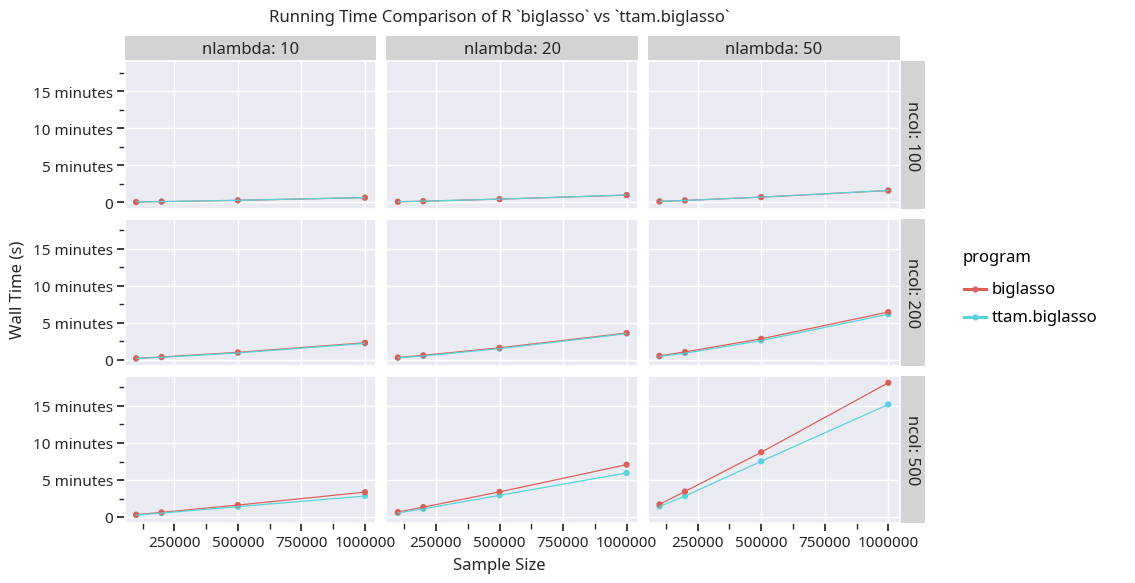

<ggplot: (8737289273628)>

In [17]:
# -- overview plot of runtimes across all the float64 configurations
df64 = df.loc[lambda f: (f.dtype == "float64")]

(
    ggplot(df64, aes(x="nrow", y="time", color="program"))
    + p9.geom_point()
    + p9.geom_line()
    + p9.facet_grid("ncol ~ nlambda", labeller="label_both")
    + p9.labs(x='Sample Size', y='Wall Time (s)')
    + p9.ggtitle("Running Time Comparison of R `biglasso` vs `pybiglasso`")
    + p9.theme(figure_size=(10, 6))
)

In [18]:
# -- compute percent change in runtime from biglasso to pybiglasso, over all benchmark pairs
dfpair = df64.drop(["alpha", "nreps", "dtype"], axis="columns")

dfjoined = (
    pd.merge(
        dfpair.loc[lambda f: f.program == "pybiglasso"],
        dfpair.loc[lambda f: f.program == "biglasso"],
        on=("nrow", "ncol", "nlambda"),
        suffixes=('_py', '_bl'),
    )
    .assign(percent_change=lambda f: (f.time_ms_py - f.time_ms_bl) / f.time_ms_py)
    .sort_values("percent_change")
)

dfjoined.percent_change.describe()

# -- pybiglasso is closer to R biglasso in performance for larger problem size
dfjoined.head(3)
dfjoined.tail(3)

count    36.000000
mean     -0.081314
std       0.106157
min      -0.219041
25%      -0.176441
50%      -0.087108
75%       0.003405
max       0.212856
Name: percent_change, dtype: float64

,program_py,time_ms_py,nrow,ncol,nlambda,time_py,program_bl,time_ms_bl,time_bl,percent_change
17,pybiglasso,170064,200000.0,500,50,0 days 00:02:50.064000,biglasso,207315,0 days 00:03:27.315000,-0.219041
16,pybiglasso,66824,200000.0,500,20,0 days 00:01:06.824000,biglasso,80757,0 days 00:01:20.757000,-0.208503
8,pybiglasso,86119,100000.0,500,50,0 days 00:01:26.119000,biglasso,103333,0 days 00:01:43.333000,-0.199886


,program_py,time_ms_py,nrow,ncol,nlambda,time_py,program_bl,time_ms_bl,time_bl,percent_change
9,pybiglasso,7059,200000.0,100,10,0 days 00:00:07.059000,biglasso,6548,0 days 00:00:06.548000,0.072390
1,pybiglasso,5835,100000.0,100,20,0 days 00:00:05.835000,biglasso,5150,0 days 00:00:05.150000,0.117395
0,pybiglasso,4247,100000.0,100,10,0 days 00:00:04.247000,biglasso,3343,0 days 00:00:03.343000,0.212856


In [20]:
# -- absolute runtimes for largest problem size benchmarked

df.loc[lambda f: (f.nrow == df.nrow.max()) & (f.ncol == df.ncol.max()) & (f.nlambda == df.nlambda.max())].sort_values("time")

,program,time_ms,nrow,ncol,nlambda,alpha,nreps,dtype,time
70,pybiglasso,912071,1000000.0,500,50,0.8,1,float64,0 days 00:15:12.071000
71,biglasso,1087861,1000000.0,500,50,0.8,1,float64,0 days 00:18:07.861000


site-packages/plotnine/facets/facet_grid.py:136: FutureWarning: Index.__and__ operating as a set operation is deprecated, in the future this will be a logical operation matching Series.__and__.  Use index.intersection(other) instead
site-packages/plotnine/facets/facet_grid.py:137: FutureWarning: Index.__and__ operating as a set operation is deprecated, in the future this will be a logical operation matching Series.__and__.  Use index.intersection(other) instead


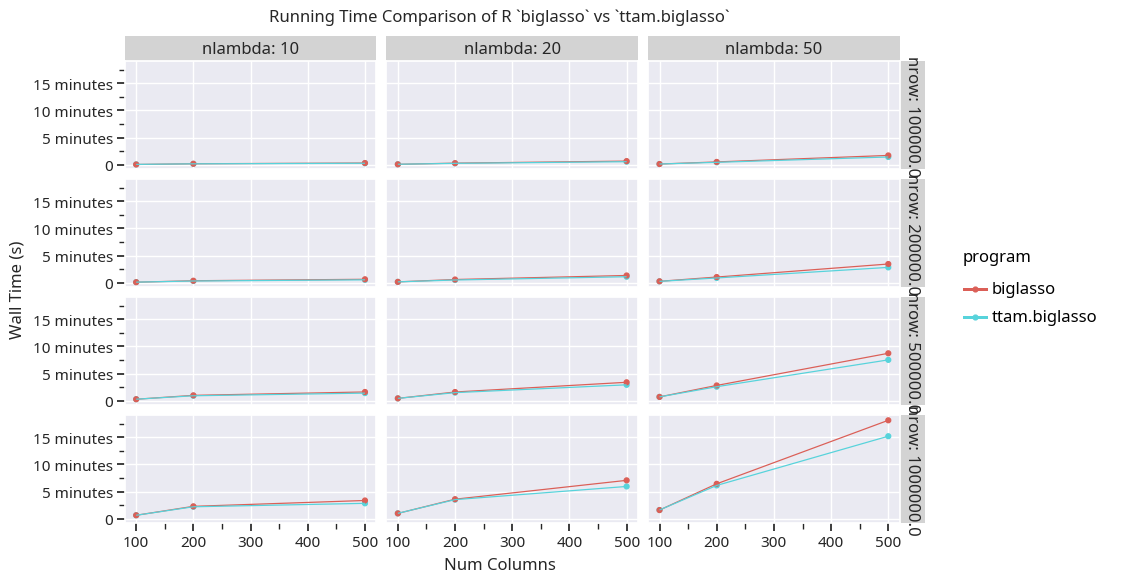

<ggplot: (8737255514194)>

site-packages/plotnine/facets/facet_grid.py:136: FutureWarning: Index.__and__ operating as a set operation is deprecated, in the future this will be a logical operation matching Series.__and__.  Use index.intersection(other) instead
site-packages/plotnine/facets/facet_grid.py:137: FutureWarning: Index.__and__ operating as a set operation is deprecated, in the future this will be a logical operation matching Series.__and__.  Use index.intersection(other) instead


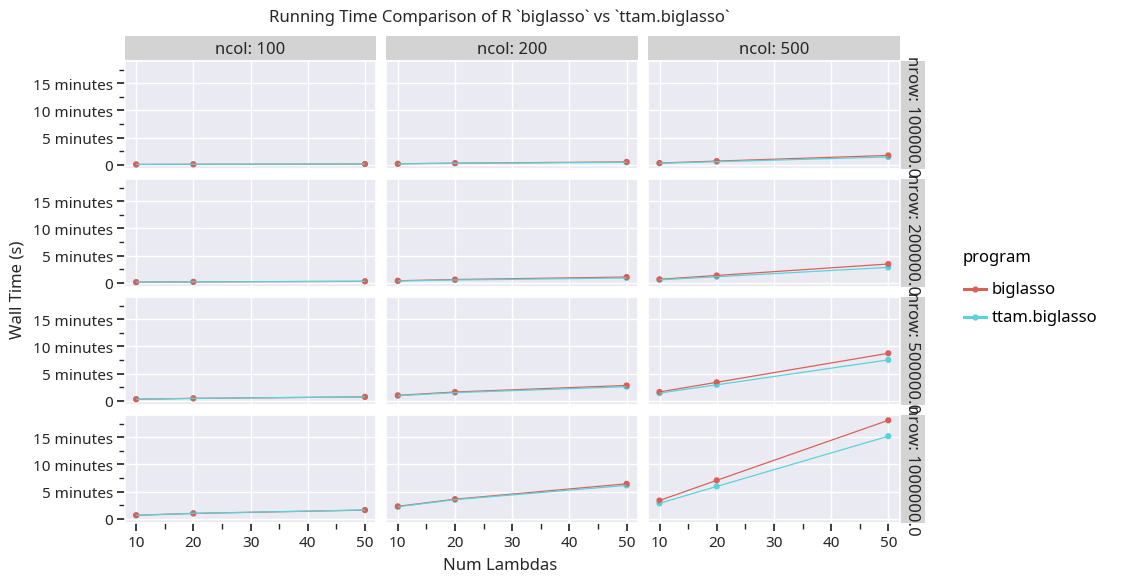

<ggplot: (8737289083335)>

In [21]:
# -- checking linearity

(
    ggplot(df64, aes(x="ncol", y="time", color="program"))
    + p9.geom_point()
    + p9.geom_line()
    + p9.facet_grid("nrow ~ nlambda", labeller="label_both")
    + p9.labs(x='Num Columns', y='Wall Time (s)')
    + p9.ggtitle("Running Time Comparison of R `biglasso` vs `pybiglasso`")
    + p9.theme(figure_size=(10, 6))
)

(
    ggplot(df64, aes(x="nlambda", y="time", color="program"))
    + p9.geom_point()
    + p9.geom_line()
    + p9.facet_grid("nrow ~ ncol", labeller="label_both")
    + p9.labs(x='Num Lambdas', y='Wall Time (s)')
    + p9.ggtitle("Running Time Comparison of R `biglasso` vs `pybiglasso`")
    + p9.theme(figure_size=(10, 6))
)